# CellVOCAL analysis of embryonic mouse gut

This tutorial models a prepared Stereo-seq embryonic gut H5AD. A spatially derived time prior orients the learned trajectory, while RNA kinetics and local ligand-receptor context determine the fitted velocity and communication influence.

> Start Jupyter from the repository root. Training is commented by default.

## Model specification

The model uses an eight-dimensional latent state and a 36-neighbor graph. The low CCC velocity scale treats communication as a modulation of the dominant intrinsic developmental dynamics rather than their sole driver.

In [1]:
from base64 import b64encode
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "model").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import anndata as ad
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display
from IPython.utils.capture import capture_output

from model.train.config import CellVOCALConfig
from pipeline.analysis import CellVOCALAnalysis
from pipeline.cellvocal import run_cellvocal
from utils.tools.real_time_prior import set_real_time_prior


In [2]:
DATA_ROOT = ROOT / "paper" / "data" / "mouse_gut"

cfg = CellVOCALConfig()
cfg.train.device = "cuda:0" if torch.cuda.is_available() else "cpu"
cfg.train.checkpoint_dir = DATA_ROOT / "cellvocal" / "checkpoints"
cfg.eval.output_dir = DATA_ROOT / "cellvocal" / "results"
cfg.model.latent_dim = 8
cfg.model.hidden_dim = 20
cfg.model.use_cell_annotation = False
cfg.model.ccc_velocity_scale = 0.025
cfg.graph.n_spatial_neighbors = 36
cfg.graph.ccc_event_budget_per_receiver = 1
cfg.train.time_prior_source = "obs"
cfg.train.time_prior_obs_key = "tprior"
cfg.train.velocity_order_min_delta = 1e-4
cfg.train.lr = 1e-4
cfg.train.w_time = 0.6

## Train CellVOCAL

The prepared H5AD already contains the smoothed RNA layers and tissue coordinates used by the method. The shared time-prior utility adds the continuous spatial prior required by this fit.

In [3]:
# adata = ad.read_h5ad(DATA_ROOT / "raw" / "stereo-seq-e14-gut_pp.h5ad")
# adata.obsm["spatial"] = np.asarray(adata.obsm["X_spatial"], dtype=float)
# set_real_time_prior(adata, "mouse_gut")
# result = run_cellvocal(adata, config=cfg)

## Evaluate the epithelial-to-mesenchymal axis

For the embryonic mouse gut, the interpretable contrast is between epithelial and mesenchymal compartments. The table reports abundance, the spatial prior, and fitted median time before the global direction metrics and spatial maps.

,spots,spots (%),prior_median,inferred_time_median
clusters,,,,
Epithelial,288,12.096,6.732,0.486
Mesenchymal,2093,87.904,14.016,0.529


,Dataset,Mouse gut
Metrics,Model,
Time Correlation,CellVOCAL,0.845
Spatial Velocity Consistency,CellVOCAL,0.958
Spatial Time Consistency,CellVOCAL,0.840
CBDir,CellVOCAL,0.120



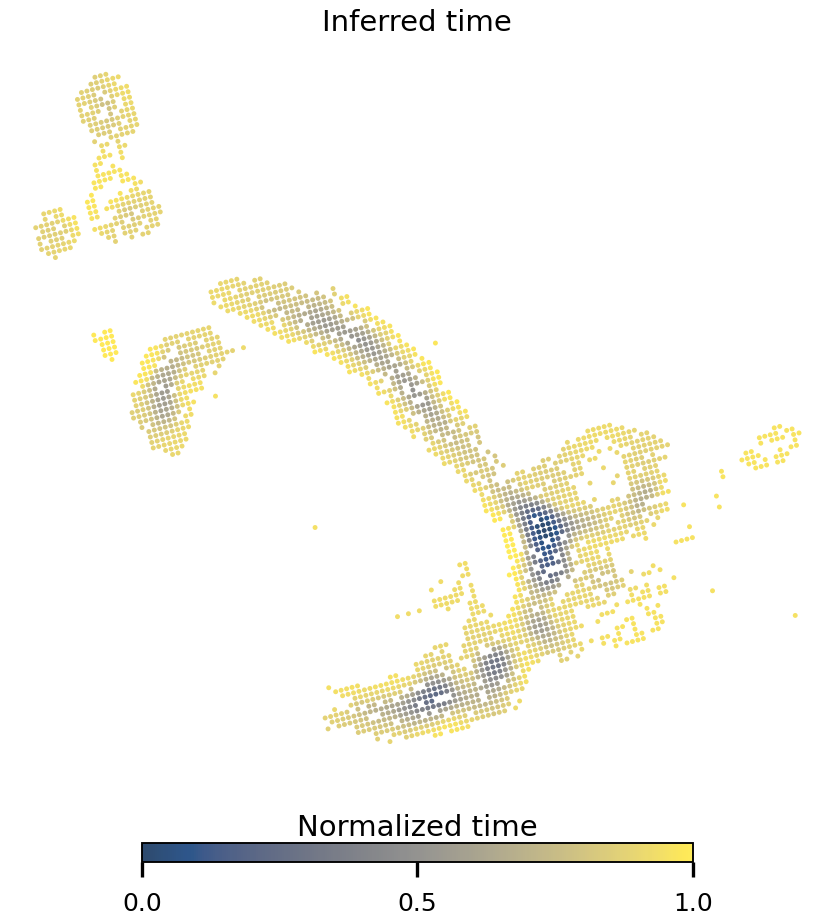
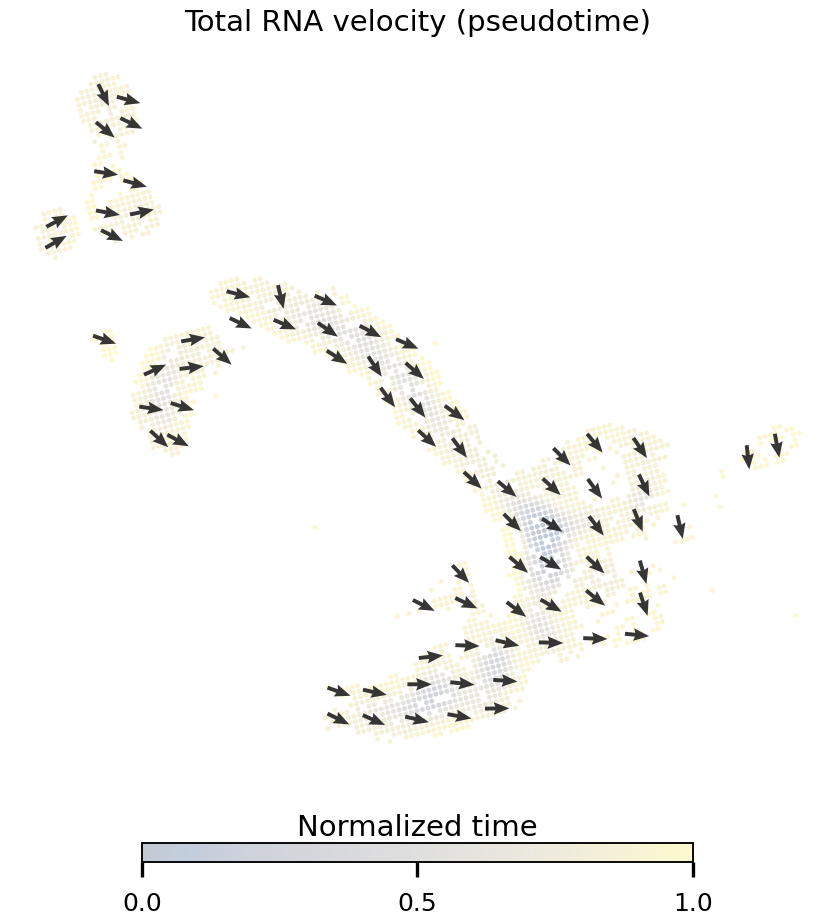
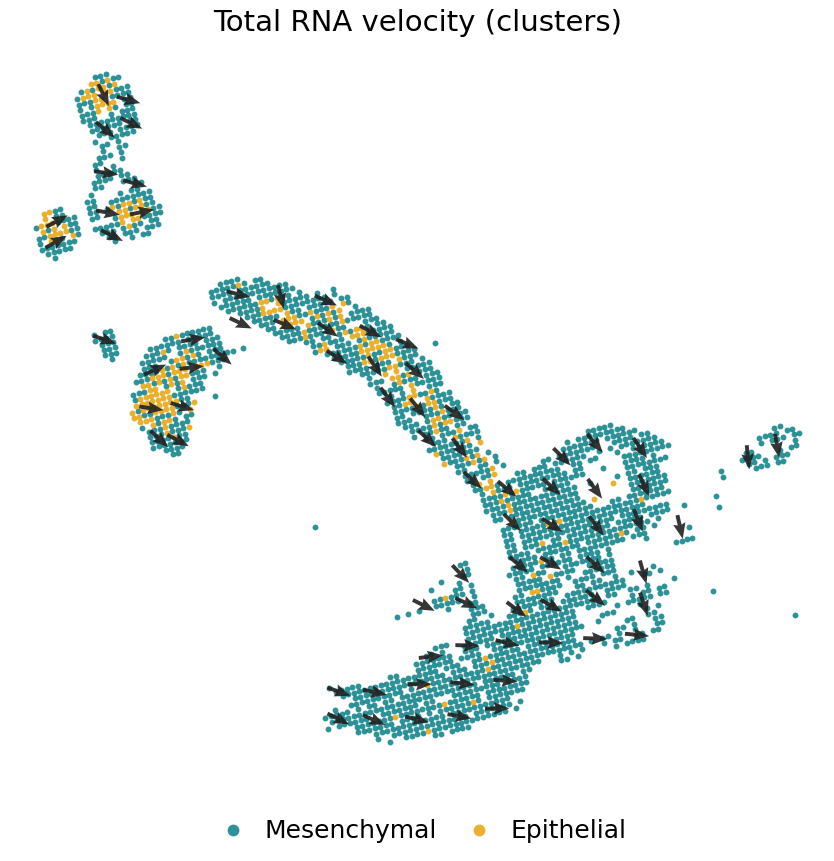

In [4]:
analysis = CellVOCALAnalysis.from_h5ad(cfg.eval.output_dir / "out.h5ad", config=cfg)
compartment_summary = analysis.adata.obs.groupby("clusters", observed=True).agg(
    spots=("cv_time", "size"), prior_median=("tprior", "median"), inferred_time_median=("cv_time", "median")
)
compartment_summary["spots (%)"] = 100 * compartment_summary["spots"] / compartment_summary["spots"].sum()
display(compartment_summary[["spots", "spots (%)", "prior_median", "inferred_time_median"]].round(3))

with capture_output():
    set_real_time_prior(analysis.adata, "mouse_gut")
    metrics = analysis.evaluate_metrics(cluster_edges=[("Epithelial", "Mesenchymal")], dataset_name="Mouse gut", n_jobs=cfg.eval.benchmark_n_jobs)
display(metrics)
with capture_output():
    velocity_plots = analysis.plot_velocity(output_dir=DATA_ROOT / "cellvocal" / "velocity")
image_tiles = []
for path in velocity_plots:
    encoded = b64encode(Path(path).read_bytes()).decode("ascii")
    image_tiles.append(f'<img src="data:image/png;base64,{encoded}" alt="{Path(path).stem}" style="flex:1 1 0;min-width:0;width:32%;height:auto;object-fit:contain">')
display(HTML('<div style="display:flex;flex-wrap:nowrap;gap:8px;align-items:flex-start;width:100%">' + "".join(image_tiles) + "</div>"))